# Phase 1 — Data understanding and baseline

**Group:** 7  
**Members:** Jake, Omeet, Maeda, Saad  
**Student numbers:** [MISSING: four student numbers]  
**Dataset:** DS-18 (home-equity loan default), OpenML **46483**  
**Target:** `bad` (binary classification)  
**Demonstration session:** [MISSING: Tue 1 Dec or Fri 4 Dec 2026]  

Person slots for human write-ups match `CHECKLIST.md` (`[Person 1]` … `[Person 4]`).


## Problem

We predict whether a home-equity loan will default (`bad` = 1) or not (`bad` = 0), using credit history, debt, and employment features.

A lender can use the prediction to decide how much risk to take on a loan application, or to prioritize accounts for review. The task is **binary classification**.

[Person 4] Polish the usefulness sentence in the group's own words before submission.


## Evaluation metric `[Person 1]`

**Working assumption (current): ROC-AUC.**

Accuracy is a poor primary metric when most loans are paid — measure the default rate in the target-distribution section before locking this choice.

**Options (group may switch before locking this write-up):**
- **ROC-AUC** (current) — ranks positives above negatives; a constant prediction has AUC **0.5** by definition (do not call `roc_auc_score` on a constant vector).
- **Per-class recall** — reports the hit rate for each class under imbalance.

The required Phase 1 baseline is still the **majority class**, scored on the **validation** rows only.


In [19]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import SEED, TARGET, apply_split, load_dataset
from src.evaluate import majority_baseline
from src.features import build_preprocessor

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = load_dataset()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print(df.shape)
df.head()


(5960, 13)


,loan,mortdue,value,reason,job,yoj,derog,delinq,clage,ninq,clno,debtinc,bad
0,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN,1
1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN,1
2,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN,1
3,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN,0


## Data dictionary `[Person 4]`

Fill **meaning** for every column (type and missingness rate are computed below). Catalog: ~5,960 rows; 10 numeric and 2 categorical predictors plus `bad`.


In [20]:
dict_rows = []
for col in df.columns:
    s = df[col]
    miss = float(s.isna().mean())
    if col == TARGET:
        kind = "target (binary)"
    elif pd.api.types.is_numeric_dtype(s):
        kind = "numeric"
    else:
        kind = "categorical"
    dict_rows.append(
        {
            "column": col,
            "type": kind,
            "missingness_rate": round(miss, 4),
            "meaning": "[MISSING: column meaning]",
        }
    )
dictionary = pd.DataFrame(dict_rows)
dictionary


,column,type,missingness_rate,meaning
0,loan,numeric,0.0000,[MISSING: column meaning]
1,mortdue,numeric,0.0869,[MISSING: column meaning]
2,value,numeric,0.0188,[MISSING: column meaning]
3,reason,categorical,0.0423,[MISSING: column meaning]
4,job,categorical,0.0468,[MISSING: column meaning]
5,yoj,numeric,0.0864,[MISSING: column meaning]
6,derog,numeric,0.1188,[MISSING: column meaning]
7,delinq,numeric,0.0973,[MISSING: column meaning]
8,clage,numeric,0.0517,[MISSING: column meaning]
9,ninq,numeric,0.0856,[MISSING: column meaning]


## Target distribution and class balance

`bad` can arrive as a pandas categorical — always use `pd.to_numeric` before a rate or mean.

**Class balance options (Phase 1):**
- **Do not resample in Phase 1** (current).
- **Resample inside the training rows only** — never before the split (that would leak).

Phase 1 only needs the class ratio and a metric that imbalance does not distort.

### Figure 1 — Target balance `[Person 1]`

**Why we measure this:** Default (`bad=1`) vs paid (`bad=0`) share decides whether accuracy is usable and which metric to lock (ROC-AUC vs per-class recall). It also sets the majority-class baseline.

**What the claim means for us:** It states which class is larger and the default rate. If defaults are the minority, a model that always says “paid” looks strong on accuracy but is useless — so we keep AUC (or recall) and treat the majority predictor as the bar Phase 2/3 must beat.


class counts:
 bad
0    4771
1    1189
Name: count, dtype: int64
default rate (bad=1): 0.1995
majority class share: 0.8005


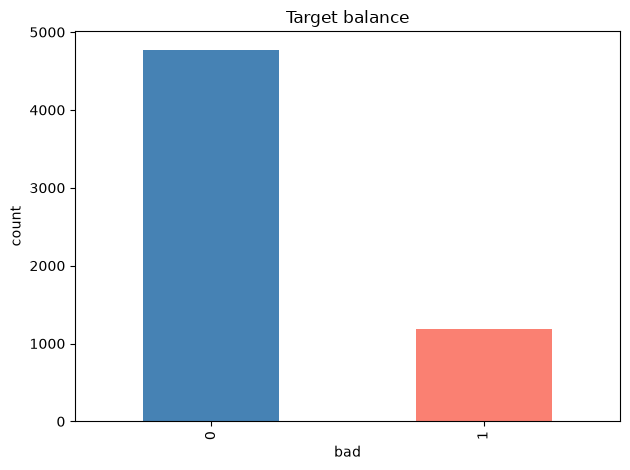

Claim: class 0 is the majority (4771 / 5960 = 0.801); default rate is 0.199.


In [21]:
rate = float(df[TARGET].mean())
counts = df[TARGET].value_counts(dropna=False).sort_index()
print("class counts:\n", counts)
print(f"default rate (bad=1): {rate:.4f}")
print(f"majority class share: {counts.max() / counts.sum():.4f}")

fig, ax = plt.subplots()
counts.plot(kind="bar", ax=ax, color=["steelblue", "salmon"])
ax.set_xlabel("bad")
ax.set_ylabel("count")
ax.set_title("Target balance")
fig.tight_layout()
fig.savefig(FIG / "01-target-balance.png", dpi=120)
plt.show()
print(
    f"Claim: class {counts.idxmax()} is the majority "
    f"({counts.max()} / {counts.sum()} = {counts.max() / counts.sum():.3f}); "
    f"default rate is {rate:.3f}."
)
# [Person 1] rewrite the claim from the printed numbers if counts change.


## Exploratory figures

At least five figures, each with a claim written from the numbers that figure prints. Saved under `results/figures/`. Which five is a group choice; the set below is the starter default.

Reference AUC bars on the DS-18 catalog card are a screening artifact, not a target.

**Thread for the project:** Figure 1 locks scoring + baseline; Figures 2–4 show whether missingness and features carry default signal for the preprocess/model story; Figure 5 locks the outlier policy so Phase 2 isn’t quietly dropping or clipping rows without a written reason.


### Figure 2 — Missingness by target `[Person 2]`

**Why we measure this:** On DS-18, missingness may track risk, not just random blanks. We need overall rates *and* rates by `bad` before choosing treatment A vs B (`add_indicator` or not).

**What the claim means for us:** It names the most-missing feature and how much its missing rate differs between `bad=0` and `bad=1`. A real gap supports option B (give the model an explicit “was missing?” flag); little/no gap means missingness is weaker evidence and we justify A/B from that.


overall missingness (top):
debtinc    0.212584
derog      0.118792
delinq     0.097315
mortdue    0.086913
yoj        0.086409
ninq       0.085570
clage      0.051678
job        0.046812
reason     0.042282
clno       0.037248
dtype: float64

missingness by target:
            bad=0     bad=1
debtinc  0.100817  0.661060
derog    0.130161  0.073171
delinq   0.106477  0.060555
mortdue  0.086355  0.089151
yoj      0.094320  0.054668
ninq     0.091176  0.063078
clage    0.048208  0.065601
job      0.053658  0.019344


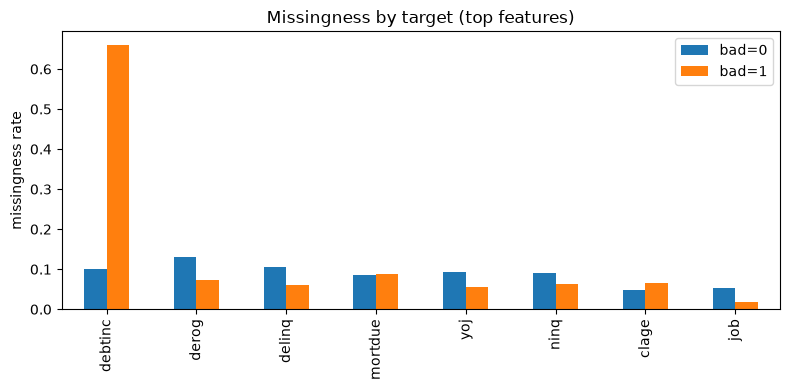

Claim: debtinc has overall missingness 0.213; rate differs by 0.560 across bad levels ({'bad=0': 0.1008174386920981, 'bad=1': 0.6610597140454163}).


In [22]:
feat_cols = [c for c in df.columns if c != TARGET]
miss_overall = df[feat_cols].isna().mean().sort_values(ascending=False)
miss_by_bad = df.groupby(TARGET)[feat_cols].apply(lambda g: g.isna().mean()).T
miss_by_bad.columns = [f"bad={int(c)}" for c in miss_by_bad.columns]
print("overall missingness (top):")
print(miss_overall.head(10))
print("\nmissingness by target:")
print(miss_by_bad.loc[miss_overall.head(8).index])

plot_df = miss_by_bad.loc[miss_overall.head(8).index]
fig, ax = plt.subplots(figsize=(8, 4))
plot_df.plot(kind="bar", ax=ax)
ax.set_ylabel("missingness rate")
ax.set_title("Missingness by target (top features)")
fig.tight_layout()
fig.savefig(FIG / "02-missingness-by-target.png", dpi=120)
plt.show()
top = miss_overall.index[0]
delta = float(miss_by_bad.loc[top].max() - miss_by_bad.loc[top].min())
print(
    f"Claim: {top} has overall missingness {miss_overall.loc[top]:.3f}; "
    f"rate differs by {delta:.3f} across bad levels "
    f"({miss_by_bad.loc[top].to_dict()})."
)


### Figure 3 — Numeric feature vs target `[Person 3]`

**Why we measure this:** Checks whether a continuous credit/loan feature (e.g. `debtinc`) actually separates defaulters from non-defaulters before we invest in modeling it.

**What the claim means for us:** It compares mean (and sample sizes) of that feature for `bad=0` vs `bad=1`. A clear shift means that feature is worth keeping in the pipeline story; almost no shift means we should not oversell it as a driver in write-ups.


     count       mean     median
bad                             
0     4290  33.253129  34.541671
1      403  39.387645  38.079762


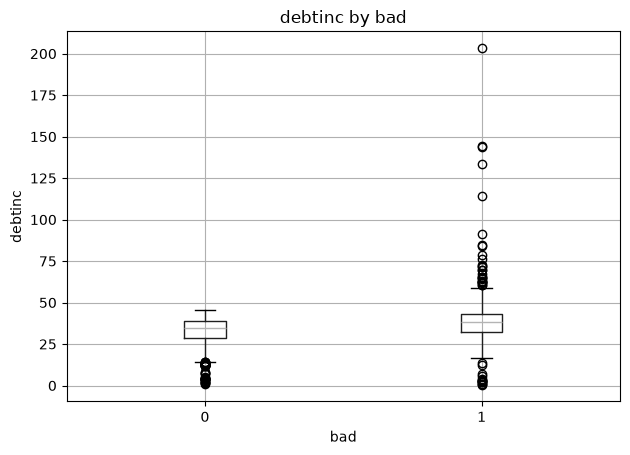

Claim: mean debtinc is 33.253 when bad=0 and 39.388 when bad=1 (n0=4290, n1=403).


In [23]:
num_cols = df.select_dtypes(include="number").columns.drop(TARGET)
# Prefer a credit-related column when present; else first numeric.
pref = [c for c in ("debtinc", "loan", "mortdue", "value", "clage") if c in num_cols]
num_feat = pref[0] if pref else num_cols[0]

grp = df.groupby(TARGET)[num_feat].agg(["count", "mean", "median"])
print(grp)

fig, ax = plt.subplots()
df.boxplot(column=num_feat, by=TARGET, ax=ax)
plt.suptitle("")
ax.set_title(f"{num_feat} by bad")
ax.set_ylabel(num_feat)
fig.tight_layout()
fig.savefig(FIG / "03-numeric-vs-target.png", dpi=120)
plt.show()
m0, m1 = float(grp.loc[0, "mean"]), float(grp.loc[1, "mean"])
print(
    f"Claim: mean {num_feat} is {m0:.3f} when bad=0 and {m1:.3f} when bad=1 "
    f"(n0={int(grp.loc[0, 'count'])}, n1={int(grp.loc[1, 'count'])})."
)


### Figure 4 — Categorical feature vs target `[Person 4]`

**Why we measure this:** Same idea for categories (`reason`, `job`, …): does membership change default risk?

**What the claim means for us:** It gives the range of P(bad=1 | category) across levels. A wide spread means category codes carry signal (one-hot / most-frequent impute still matters); a flat spread means that factor is weak for ranking risk.


P(bad | category):
bad             0         1
reason                     
DebtCon  0.810336  0.189664
HomeImp  0.777528  0.222472

counts:
bad         0    1
reason            
DebtCon  3183  745
HomeImp  1384  396


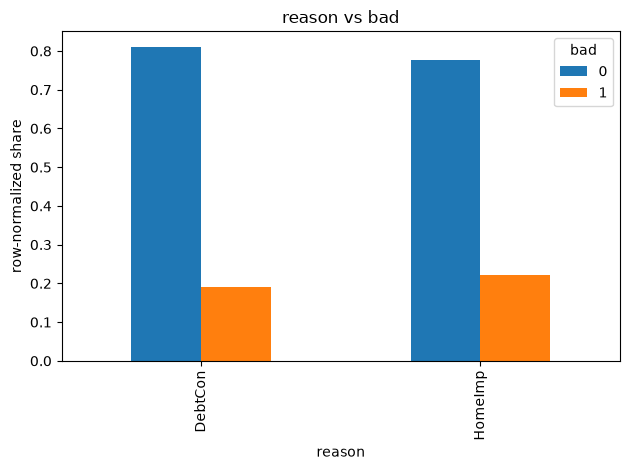

Claim: P(bad=1 | reason) ranges 0.190–0.222 (spread 0.033) across levels.


In [24]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
cat_feat = cat_cols[0] if cat_cols else None
if cat_feat is None:
    raise RuntimeError("No categorical columns found; pick another figure.")

ct = pd.crosstab(df[cat_feat], df[TARGET], normalize="index")
print("P(bad | category):")
print(ct)
counts_ct = pd.crosstab(df[cat_feat], df[TARGET])
print("\ncounts:")
print(counts_ct)

fig, ax = plt.subplots()
ct.plot(kind="bar", ax=ax)
ax.set_ylabel("row-normalized share")
ax.set_title(f"{cat_feat} vs bad")
fig.tight_layout()
fig.savefig(FIG / "04-categorical-vs-target.png", dpi=120)
plt.show()
spread = float(ct[1].max() - ct[1].min()) if 1 in ct.columns else float("nan")
print(
    f"Claim: P(bad=1 | {cat_feat}) ranges {ct[1].min():.3f}–{ct[1].max():.3f} "
    f"(spread {spread:.3f}) across levels."
)


## Missing values and outliers

### Missing values `[Person 2]`

Catalog note: several columns are genuinely missing, and missingness can be informative for default. Measure overall and by `bad` (figure above) before locking the choice.

**Options:**
- **(A)** §3.3 as written — median then scale; most-frequent then one-hot; report informativeness in the notebook only.
- **(B)** current — A, plus `add_indicator=True` on the **numeric** imputer only. Leave the categorical imputer without `add_indicator` unless the group writes why.

### Outliers `[Person 3]`

Identify them and state a decision. Removal is not the default. A 1.5-IQR rule is a reasonable screen.

**Options:**
- **Keep every row** (current) and document the screen.
- **Cap** named columns.
- **Drop** rows only with a justification other than “they failed the fence.”

An IQR fence is still defined when the spread is 0. Zero-inflated counts can fall outside a fence at zero — that is a reason to **keep** those rows.

### Figure 5 — Outlier screen (1.5-IQR) `[Person 3]`

**Why we measure this:** Extreme values are common in loan/credit data. We screen so the keep / cap / drop decision is based on counts, not vibes. The fence is diagnostic, not an auto-delete rule.

**What the claim means for us:** It says which column breaches the fence most, how often, and that rows are kept. Lots of “outliers” (especially zero-inflated counts) usually argue for **keep-all**; we only cap/drop with a reason other than “failed the fence.”


 column          iqr           low          high  n_outside  pct_outside
 delinq     0.000000      0.000000      0.000000       1201     0.201510
  derog     0.000000      0.000000      0.000000        725     0.121644
  value 53748.750000 -14547.625000 200447.375000        320     0.053691
   loan 12200.000000  -7200.000000  41600.000000        256     0.042953
mortdue 45212.000000 -21542.000000 159306.000000        234     0.039262
   clno    11.000000     -1.500000     42.500000        219     0.036745
   ninq     2.000000     -3.000000      5.000000        177     0.029698
debtinc     9.863109     14.345367     53.797805         94     0.015772
    yoj    10.000000    -12.000000     28.000000         91     0.015268
  clage   116.445576    -59.551662    406.230642         47     0.007886
Decision: keep every row; screen is diagnostic only.


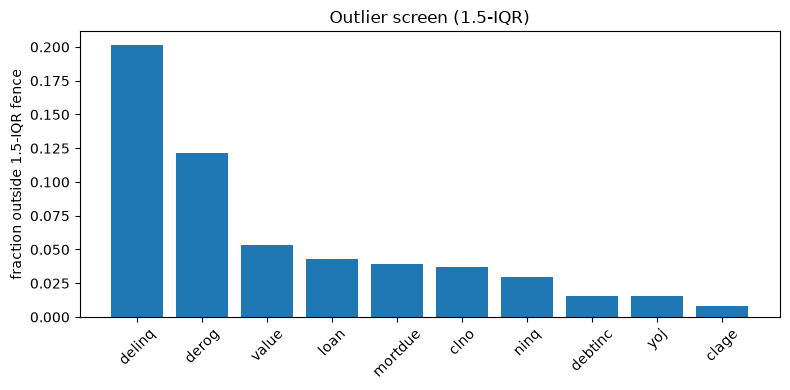

Claim: delinq has the most fence breaches (1201 rows, 0.202 of the frame); IQR=0. Rows are kept.


In [25]:
# 1.5-IQR screen on numeric predictors (document only; keep every row).
# Other options (not applied): cap named columns; drop rows with a non-fence justification.
num_pred = df.select_dtypes(include="number").columns.drop(TARGET)
fence_rows = []
for col in num_pred:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outside = int(((df[col] < low) | (df[col] > high)).sum())
    fence_rows.append(
        {
            "column": col,
            "iqr": float(iqr),
            "low": float(low),
            "high": float(high),
            "n_outside": outside,
            "pct_outside": outside / len(df),
        }
    )
fence = pd.DataFrame(fence_rows).sort_values("n_outside", ascending=False)
print(fence.to_string(index=False))
print("Decision: keep every row; screen is diagnostic only.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(fence["column"], fence["pct_outside"])
ax.set_ylabel("fraction outside 1.5-IQR fence")
ax.set_title("Outlier screen (1.5-IQR)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIG / "05-outlier-screen.png", dpi=120)
plt.show()
top = fence.iloc[0]
print(
    f"Claim: {top['column']} has the most fence breaches "
    f"({int(top['n_outside'])} rows, {top['pct_outside']:.3f} of the frame); "
    f"IQR={top['iqr']:.4g}. Rows are kept."
)


## Declared train / validation / test split `[Person 2]`

Seed **3000**. Two stratified splits (§7.3): 20% test, then 25% of the remainder as validation (60% / 20% / 20%). Indices are saved to `data/splits/split_seed3000.npz` and reloaded thereafter — do not call `train_test_split` again with a different seed.

**Freeze the test set here.** `apply_split` returns `X_test` / `y_test`, but do not use them until Phase 3.


In [26]:
X_train, X_val, X_test, y_train, y_val, y_test = apply_split(df)
print(f"SEED={SEED}")
print(f"train={len(X_train)}, val={len(X_val)}, test={len(X_test)} (unused until Phase 3)")
print("train bad rate:", float(y_train.mean()))
print("val bad rate:", float(y_val.mean()))


ValueError: not enough values to unpack (expected 6, got 5)

## Baseline (majority class on validation) `[Person 1]`

Primary metric working assumption: **ROC-AUC**. A constant prediction has AUC **0.5**; we do not call `roc_auc_score` on a constant vector.

If the group switches to **per-class recall**, the same majority baseline would be scored with `recall_score` per class instead.


In [ ]:
majority, acc, auc_constant = majority_baseline(y_val.to_numpy())
print(f"majority label on validation: {majority}")
print(f"majority-class accuracy (val): {acc:.4f}")
print(f"ROC-AUC for any constant prediction: {auc_constant:.1f} (not from roc_auc_score)")


majority label on validation: 0
majority-class accuracy (val): 0.8003
ROC-AUC for any constant prediction: 0.5 (not from roc_auc_score)


## Preprocessing pipeline `[Person 2]`

Fit on **training rows only**; transform validation. Never `fit_transform` validation or test. Missingness option **B** is active in `src/features.py` (option A left as a comment there).


In [ ]:
prep = build_preprocessor(X_train)
prep.fit(X_train)  # training data ONLY
X_train_p = prep.transform(X_train)
X_val_p = prep.transform(X_val)  # transform, never fit_transform
print("X_train_p", X_train_p.shape, "X_val_p", X_val_p.shape)
print(f"test rows held out (not transformed for scoring): {len(X_test)}")


X_train_p (3576, 27) X_val_p (1192, 27)
test rows sealed (not transformed for scoring): 1192


## Prior work (§9.1) `[Person 4]`

[MISSING: list any public analyses of this dataset you opened, and what this project does differently. If you used none, write that here.]


## AI use (§8)

Not a Person slot — anyone who uses AI exports the session and keeps the index honest.

[MISSING: group statement in your own words — three or four sentences: what AI was used for, what was accepted, what was rejected, and whether it changed a decision.]

### Index

| Transcript | Tool | Purpose | What you changed |
|------------|------|---------|------------------|
| `ai-log/phase1-01-phase1-planning.md` | Cursor Agent (Composer); model version was not shown in the export | Plan Phase 1 starter tree, checklist, notebook order, group choices | Accepted working assumptions (ROC-AUC, missingness B, keep-all outliers, no resample). Required listing alternate options beside each assumption. Rejected named-person tracks and an integrator role (Person 1–4 blank mapping only). |
| `ai-log/phase1-02-phase1-implementation.md` | Cursor Agent (Composer); model version was not shown in the export | Implement §7.1 tree, `src/`, phase1 notebook, figures, AI log | Accepted starter tree, notebook, figures, and frozen split as the base. After review, rejected committing `.venv`; rejected making uv mandatory or naming it in the README; rejected committing uv lock/project artifacts. Also required the checklist to follow real work order (not a flat task dump). |
| `ai-log/phase1-03-checklist-person-guides.md` | Cursor Agent (Composer); model version was not shown in the export | Rebalance Person 1–4 workload; figure why/claim notes; checklist tips; rewrite PERSON-GUIDES; drop AI log as a Person slot | Accepted: problem→P4, split→P2; AI (§8) is everyone’s logging duty, not a shepherd; figure explanations in notebook; tips under checklist tasks; PERSON-GUIDES rewritten. Rejected: assigning one person as AI log shepherd. |

This table is also kept in `ai-log/INDEX.md`.
